In [5]:
import numpy as np, h5py, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

f = h5py.File('C:/Users/user/Downloads/sample_2e7_design_precessing_higherordermodes_3detectors.h5', 'r')
N = 200_000                                  # parti con 1e5, poi aumenta
names = ['mtot','q','chi1x','chi1y','chi1z','chi2x','chi2y','chi2z','ra','dec','iota','psi','z']
X = np.column_stack([f[n][:N] for n in names])
y = f['det'][:N].astype(int)
print("frazione rivelabili:", y.mean())

frazione rivelabili: 0.144365


In [6]:
X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_tmp, y_tmp, test_size=0.25, random_state=42, stratify=y_tmp)

In [7]:
def metrics(clf, X_, y_):
    yp = clf.predict(X_)
    tn, fp, fn, tp = confusion_matrix(y_, yp).ravel()
    return tp/(tp+fn), fp/(tp+fp)           # completeness, contamination

C:\Users\user\AppData\Local\Temp\ipykernel_29096\3438632183.py:4: RuntimeWarning: invalid value encountered in scalar divide
  return tp/(tp+fn), fp/(tp+fp)           # completeness, contamination
C:\Users\user\AppData\Local\Temp\ipykernel_29096\3438632183.py:4: RuntimeWarning: invalid value encountered in scalar divide
  return tp/(tp+fn), fp/(tp+fp)           # completeness, contamination


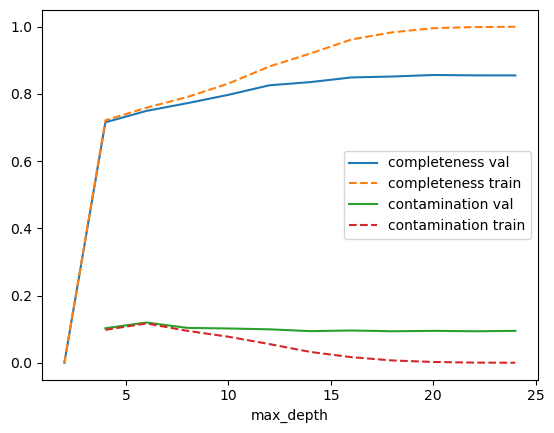

In [8]:
depths = range(2, 25, 2)
res = []
for d in depths:
    rf = RandomForestClassifier(n_estimators=100, max_depth=d, n_jobs=-1, random_state=0)
    rf.fit(X_train, y_train)
    res.append((*metrics(rf, X_train, y_train), *metrics(rf, X_val, y_val)))
res = np.array(res)
plt.plot(depths, res[:,2], label='completeness val'); plt.plot(depths, res[:,0], '--', label='completeness train')
plt.plot(depths, res[:,3], label='contamination val'); plt.plot(depths, res[:,1], '--', label='contamination train')
plt.xlabel('max_depth'); plt.legend();

In [9]:
from astropy.cosmology import Planck18
z = f['z'][:N]
dL = Planck18.luminosity_distance(z).value          # Mpc; può essere lento: calcolalo su una griglia e interpola
mtot, q = f['mtot'][:N], f['q'][:N]
extra = np.column_stack([
    mtot*(1+z),                                      # massa nel sistema del rivelatore
    mtot*(1+z) * q**0.6/(1+q)**1.2,                  # chirp mass nel sistema del rivelatore
    np.log10(dL),
    np.cos(f['iota'][:N]),
])
X2 = np.column_stack([X, extra])

In [12]:
X2_tmp, X2_test, y_tmp, y_test = train_test_split(
    X2, y, test_size=0.2, random_state=42, stratify=y)
X2_train, X2_val, y_train, y_val = train_test_split(
    X2_tmp, y_tmp, test_size=0.25, random_state=42, stratify=y_tmp)

c:\Users\user\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\user\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\user\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\user\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\user\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(

AUC test: 0.9977601902358658


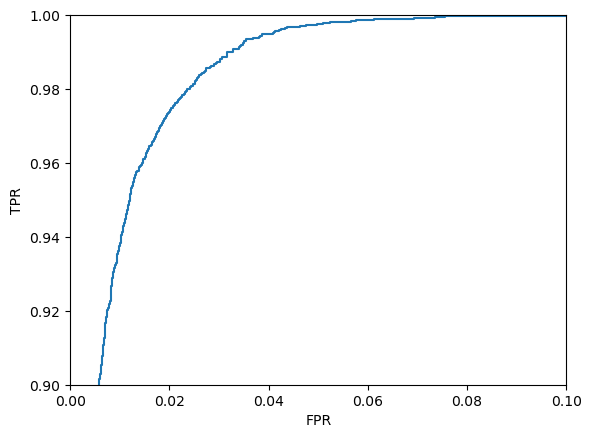

In [13]:
clf = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.1, random_state=0)
clf.fit(X2_train, y_train)                           # X2_train da split di X2, stesso random_state
p = clf.predict_proba(X2_test)[:, 1]
fpr, tpr, thr = roc_curve(y_test, p)
print("AUC test:", roc_auc_score(y_test, p))
plt.plot(fpr, tpr); plt.xlim(0, 0.1); plt.ylim(0.9, 1); plt.xlabel('FPR'); plt.ylabel('TPR');

In [14]:
thr_grid = np.linspace(0.05, 0.95, 19)
for t in thr_grid[::3]:
    yp = (p > t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, yp).ravel()
    print(f"soglia={t:.2f}  completeness={tp/(tp+fn):.3f}  contamination={fp/(tp+fp):.3f}")

soglia=0.05  completeness=0.998  contamination=0.250
soglia=0.20  completeness=0.984  contamination=0.139
soglia=0.35  completeness=0.964  contamination=0.089
soglia=0.50  completeness=0.936  contamination=0.058
soglia=0.65  completeness=0.895  contamination=0.035
soglia=0.80  completeness=0.833  contamination=0.016
soglia=0.95  completeness=0.677  contamination=0.005
